# Function Visualization

Notebook tạo các interactive visualization (Plotly) và export thành HTML độc lập cho GitHub Pages.

> 📊 GitHub chỉ hiển thị **ảnh tĩnh** của biểu đồ (GitHub không chạy JavaScript). Xem bản **tương tác**: [Hàm số bậc nhất](https://tlh222k.github.io/ai-from-scratch/visualizations/linear_function.html) · [Hàm số bậc hai](https://tlh222k.github.io/ai-from-scratch/visualizations/quadratic_function.html) · [Giới hạn của hàm số](https://tlh222k.github.io/ai-from-scratch/visualizations/limit_function.html)

**Chạy bằng `Restart Kernel → Run All`.** Output: `visualizations/linear_function.html`, `quadratic_function.html`, `index.html`.

# Nhập thư viện

In [1]:
import sys
import numpy as np
import plotly
import plotly.graph_objects as go
import plotly.io as pio

from pathlib import Path
from IPython.display import display, HTML

print("=" * 50)
print("FUNCTION VISUALIZATION")
print("=" * 50)

print(f"Python: {sys.version.split()[0]}")
print(f"Python executable: {sys.executable}")
print(f"NumPy: {np.__version__}")
print(f"Plotly: {plotly.__version__}")

FUNCTION VISUALIZATION
Python: 3.13.18
Python executable: /usr/local/bin/python3
NumPy: 2.5.3
Plotly: 7.1.0


# Cấu hình dự án

In [2]:
def find_project_root(start_path=None):
    """
    Find the root directory of ai-from-scratch.

    The project root must contain:
        - phases/
        - visualizations/
    """

    current_path = Path(start_path or Path.cwd()).resolve()

    for path in [current_path, *current_path.parents]:

        has_phases = (path / "phases").is_dir()
        has_visualizations = (path / "visualizations").is_dir()

        if has_phases and has_visualizations:
            return path

    raise FileNotFoundError(
        "Cannot find project root. "
        "Expected 'phases/' and 'visualizations/' directories."
    )


# Detect project root
PROJECT_ROOT = find_project_root()

# Define directories
VISUALIZATION_DIR = PROJECT_ROOT / "visualizations"

NOTEBOOK_DIR = VISUALIZATION_DIR / "notebooks"

# Create directories if they do not exist
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)


print("Project root:", PROJECT_ROOT)
print("Visualization directory:", VISUALIZATION_DIR)
print("Notebook directory:", NOTEBOOK_DIR)

Project root: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch
Visualization directory: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations
Notebook directory: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/notebooks


# Cấu hình hiển thị (Jupyter + GitHub)

Output gồm **cả hai**: `application/vnd.plotly.v1+json` (tương tác trong Jupyter/VS Code) và `image/png` (ảnh tĩnh để GitHub hiển thị). Cần `pip install kaleido`.

In [3]:
# Interactive in Jupyter/VS Code + static PNG fallback for GitHub
pio.renderers.default = "plotly_mimetype+png"

GITHUB_USER = "tlh222k"
REPO_NAME = "ai-from-scratch"

PAGES_BASE = f"https://{GITHUB_USER}.github.io/{REPO_NAME}/visualizations"

print("Renderer:", pio.renderers.default)
print("Pages base URL:", PAGES_BASE)

Renderer: plotly_mimetype+png
Pages base URL: https://tlh222k.github.io/ai-from-scratch/visualizations


# Hàm cấu hình biểu đồ dùng chung

Chỉ định nghĩa **một** lần `configure_figure()` (bản đầy đủ tham số). Trước đây hàm này bị định nghĩa hai lần nên bản thứ hai (thiếu `xaxis_title`, `yaxis_title`) ghi đè bản đầu.

In [4]:
def configure_figure(
    fig,
    title,
    xaxis_title="x",
    yaxis_title="y",
    height=520
):
    """
    Configure common Plotly figure settings.

    Parameters
    ----------
    fig : go.Figure
        Plotly figure.

    title : str
        Figure title.

    xaxis_title : str
        X-axis label.

    yaxis_title : str
        Y-axis label.

    height : int
        Figure height in pixels.
    """

    fig.update_layout(
        title={
            "text": title,
            "x": 0.5,
            "xanchor": "center",
            "font": {
                "size": 22
            }
        },

        autosize=True,
        height=height,

        margin=dict(
            l=60,
            r=30,
            t=110,   # room for title + horizontal legend
            b=60
        ),

        template="plotly_white",

        font=dict(
            family="Arial, sans-serif",
            size=14
        ),

        hovermode="closest",

        xaxis_title=xaxis_title,
        yaxis_title=yaxis_title,

        xaxis=dict(
            showgrid=True,
            zeroline=True,
            zerolinewidth=2,
            zerolinecolor="#64748b"
        ),

        yaxis=dict(
            showgrid=True,
            zeroline=True,
            zerolinewidth=2,
            zerolinecolor="#64748b"
        ),

        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="center",
            x=0.5
        )
    )

    return fig

# Hàm tạo chú thích (caption) dùng chung

In [5]:
def build_caption_html(
    caption,
    title=None,
    font_size="16px"
):
    """
    Generate reusable HTML caption.

    The caption accepts trusted HTML and LaTeX.
    """

    title_html = ""

    if title:

        title_html = f"""
        <h3 class="caption-title">
            {title}
        </h3>
        """

    return f"""
    <div class="visualization-caption">

        {title_html}

        <div class="caption-content">
            {caption}
        </div>

    </div>

    <style>

        .visualization-caption {{
            width: 100%;
            box-sizing: border-box;

            margin-top: 16px;
            padding: 18px 22px;

            background: #f8fafc;

            border-left: 4px solid #2563eb;
            border-radius: 8px;

            font-size: {font_size};
            line-height: 1.8;

            color: #334155;

            overflow-wrap: break-word;
        }}

        .caption-title {{
            margin: 0 0 10px 0;

            font-size: 20px;
            font-weight: 700;

            color: #0f172a;
        }}

        .caption-content strong {{
            color: #1d4ed8;
        }}

        @media (max-width: 600px) {{

            .visualization-caption {{
                padding: 14px;
                font-size: 14px;
            }}

            .caption-title {{
                font-size: 17px;
            }}

        }}

    </style>
    """


def add_caption(
    fig,
    caption,
    title=None,
    font_size="16px",
    html_name=None
):
    """
    Display Plotly figure with HTML caption in Jupyter.

    Output contains interactive JSON + static PNG (shown by GitHub).
    If html_name is given, a link to the interactive GitHub Pages
    version is displayed below the figure.
    """

    fig.show()

    if html_name:
        display(HTML(
            f'<p>🔗 <a href="{PAGES_BASE}/{html_name}" target="_blank">'
            f'Mở bản tương tác</a> (GitHub Pages)</p>'
        ))

    caption_html = build_caption_html(
        caption=caption,
        title=title,
        font_size=font_size
    )

    display(HTML(caption_html))

# Xuất HTML responsive

- Plotly.js được nhúng trực tiếp (`include_plotlyjs=True`) nên biểu đồ chạy **offline**.
- MathJax tải qua CDN → **cần Internet** để render công thức LaTeX (biểu đồ vẫn hoạt động nếu offline).

In [6]:
def export_figure(
    fig,
    filename,
    caption,
    caption_title=None,
    page_title=None,
    font_size="16px"
):
    """
    Export Plotly figure and HTML caption
    into a standalone responsive HTML file.

    Plotly.js is embedded locally in the HTML (works offline).
    MathJax is loaded through CDN (Internet required for formulas).
    """

    output_path = VISUALIZATION_DIR / filename

    # Generate Plotly HTML
    plot_html = fig.to_html(
        full_html=False,

        include_plotlyjs=True,

        config={
            "responsive": True,
            "displaylogo": False,
            "scrollZoom": True
        }
    )

    # Generate caption HTML
    caption_html = build_caption_html(
        caption=caption,
        title=caption_title,
        font_size=font_size
    )

    document_title = page_title or caption_title or filename

    # Combine everything into one HTML document
    # NOTE: the string must start with <!DOCTYPE html> (no leading
    # whitespace) so browsers never fall back to quirks mode.
    html_document = f"""<!DOCTYPE html>
<html lang="vi">

<head>

    <meta charset="UTF-8">

    <meta name="viewport"
          content="width=device-width, initial-scale=1.0">

    <title>{document_title}</title>

    <!-- MathJax config: \\( ... \\) inline, \\[ ... \\] display -->
    <script>
        window.MathJax = {{
            tex: {{
                inlineMath: [['\\\\(', '\\\\)']],
                displayMath: [['\\\\[', '\\\\]']]
            }}
        }};
    </script>

    <!-- MathJax is loaded from a CDN: Internet is required to render formulas -->
    <script
        id="MathJax-script"
        async
        src="https://cdn.jsdelivr.net/npm/mathjax@3/es5/tex-chtml.js">
    </script>

    <style>

        * {{
            box-sizing: border-box;
        }}

        body {{
            margin: 0;
            padding: 24px;

            font-family: Arial, sans-serif;

            background: #ffffff;
            color: #1e293b;
        }}

        .container {{
            width: 100%;
            max-width: 1100px;

            margin: 0 auto;
        }}

        .back-link {{
            display: inline-block;
            margin-bottom: 12px;

            color: #2563eb;
            text-decoration: none;
            font-size: 14px;
        }}

        .back-link:hover {{
            text-decoration: underline;
        }}

        .plot-container {{
            width: 100%;
        }}

        .note {{
            margin-top: 12px;

            color: #94a3b8;
            font-size: 12px;
            text-align: center;
        }}

        @media (max-width: 600px) {{

            body {{
                padding: 10px;
            }}

        }}

    </style>

</head>

<body>

    <main class="container">

        <a class="back-link" href="./index.html">&larr; Tất cả trực quan hoá</a>

        <section class="plot-container">

            {plot_html}

        </section>

        <section>

            {caption_html}

        </section>

        <p class="note">
            Công thức toán được hiển thị bằng MathJax và cần kết nối Internet.
            Biểu đồ tương tác vẫn hoạt động khi offline.
        </p>

    </main>

</body>

</html>
"""

    # Write HTML file
    output_path.write_text(
        html_document,
        encoding="utf-8"
    )

    size_kb = output_path.stat().st_size / 1024

    print(f"Exported successfully: {output_path}")
    print(f"File size: {size_kb:.2f} KB")

    return output_path

# Định nghĩa hàm số bậc nhất

In [7]:
def linear_function(x):
    """
    Linear function: f(x) = 2x + 1
    """
    return 2 * x + 1


# Generate input values
x_linear = np.linspace(-10, 10, 200)

# Calculate output values
y_linear = linear_function(x_linear)


print("Hàm số bậc nhất: f(x) = 2x + 1")
print("Number of data points:", len(x_linear))

Hàm số bậc nhất: f(x) = 2x + 1
Number of data points: 200


# Tạo biểu đồ hàm số bậc nhất

In [8]:
fig_linear = go.Figure()


# Add linear function
fig_linear.add_trace(
    go.Scatter(

        x=x_linear,
        y=y_linear,

        mode="lines",

        name="f(x) = 2x + 1",

        line=dict(
            width=3
        ),

        hovertemplate=(
            "x = %{x:.2f}<br>"
            "f(x) = %{y:.2f}"
            "<extra></extra>"
        )

    )
)


# Add y-intercept
fig_linear.add_trace(
    go.Scatter(

        x=[0],
        y=[1],

        mode="markers",

        name="Tung độ gốc (0, 1)",

        marker=dict(
            size=11,
            symbol="circle"
        ),

        hovertemplate=(
            "Tung độ gốc<br>"
            "(%{x}, %{y})"
            "<extra></extra>"
        )

    )
)


# Configure figure (displayed together with its caption in the next cell)
fig_linear = configure_figure(
    fig=fig_linear,

    title="Hàm số bậc nhất: f(x) = 2x + 1",

    xaxis_title="Đầu vào (x)",

    yaxis_title="Đầu ra f(x)"
)

# Thêm chú thích cho hàm số bậc nhất

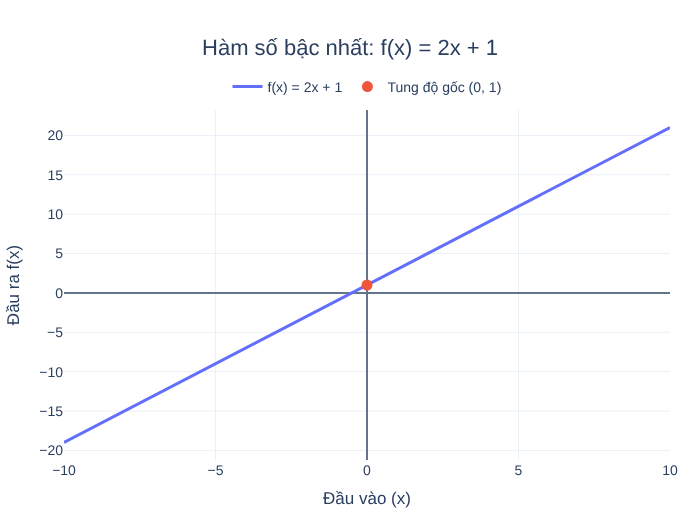

In [9]:
linear_caption = r"""
<strong>Hàm số bậc nhất</strong> có dạng \(f(x)=mx+b\).
Ở đây, \(f(x)=2x+1\) và đồ thị của nó là một <strong>đường thẳng</strong>.

<br><br>

<strong>Hệ số góc (slope)</strong> là \(m=2\).

Điều này có nghĩa là mỗi khi \(x\) tăng thêm 1 đơn vị,
giá trị \(f(x)\) tăng thêm 2 đơn vị.

<br><br>

<strong>Tung độ gốc (y-intercept)</strong> là \(b=1\).

Do đó, đường thẳng cắt trục y tại điểm:

\[
(0,1)
\]

<br>

<strong>Vì sao đồ thị là một đường thẳng?</strong>

Vì tốc độ thay đổi luôn không đổi:

\[
\frac{f(x+1)-f(x)}{1}=2
\]

với mọi giá trị của \(x\). Tốc độ thay đổi không đổi luôn tạo ra một đường thẳng.
"""


add_caption(
    fig=fig_linear,

    caption=linear_caption,

    title="Tìm hiểu hàm số bậc nhất",

    html_name="linear_function.html"
)

# Xuất HTML hàm số bậc nhất

In [10]:
export_figure(
    fig=fig_linear,

    filename="linear_function.html",

    caption=linear_caption,

    caption_title="Tìm hiểu hàm số bậc nhất",

    page_title="Hàm số bậc nhất - AI From Scratch"
)

Exported successfully: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/linear_function.html
File size: 4719.57 KB


PosixPath('/tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/linear_function.html')

# Định nghĩa hàm số bậc hai

In [11]:
def quadratic_function(x):
    """
    Quadratic function: g(x) = x²
    """
    return x ** 2


# Generate input values
x_quadratic = np.linspace(-5, 5, 300)

# Calculate output values
y_quadratic = quadratic_function(x_quadratic)


# Explicit data points (computed from the function, not hard-coded)
x_points = np.array([-2, -1, 0, 1, 2])

y_points = quadratic_function(x_points)

assert list(y_points) == [4, 1, 0, 1, 4]


print("Hàm số bậc hai: g(x) = x²")

print("\nData points:")

for x, y in zip(x_points, y_points):

    print(f"({x}, {y})")

Hàm số bậc hai: g(x) = x²

Data points:
(-2, 4)
(-1, 1)
(0, 0)
(1, 1)
(2, 4)


# Tạo biểu đồ hàm số bậc hai

In [12]:
fig_quadratic = go.Figure()


# Add quadratic function
fig_quadratic.add_trace(
    go.Scatter(

        x=x_quadratic,
        y=y_quadratic,

        mode="lines",

        name="g(x) = x²",

        line=dict(
            width=3
        ),

        hovertemplate=(
            "x = %{x:.2f}<br>"
            "g(x) = %{y:.2f}"
            "<extra></extra>"
        )

    )
)


# Add explicit data points
fig_quadratic.add_trace(
    go.Scatter(

        x=x_points,
        y=y_points,

        mode="markers",

        name="Các điểm nổi bật",

        marker=dict(
            size=11,
            symbol="circle",
            line=dict(
                width=1
            )
        ),

        hovertemplate=(
            "Điểm: (%{x}, %{y})"
            "<extra></extra>"
        )

    )
)


# Configure figure (displayed together with its caption in the next cell)
fig_quadratic = configure_figure(
    fig=fig_quadratic,

    title="Hàm số bậc hai: g(x) = x²",

    xaxis_title="Đầu vào (x)",

    yaxis_title="Đầu ra g(x)"
)

# Thêm chú thích cho hàm số bậc hai

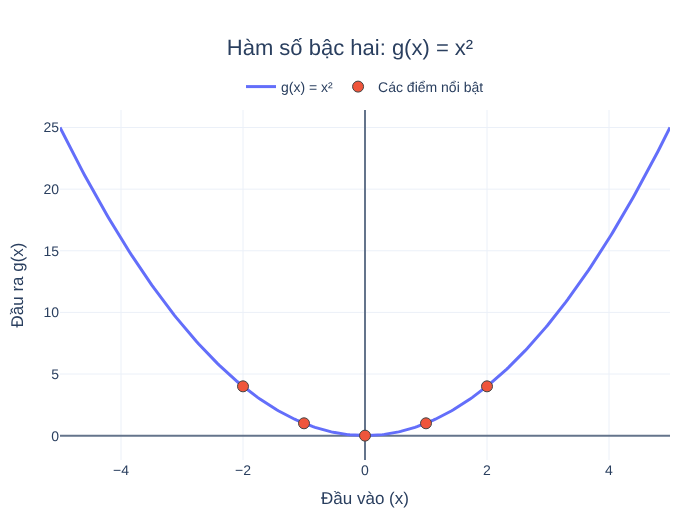

In [13]:
quadratic_caption = r"""
<strong>Hàm số bậc hai</strong> có dạng
\(g(x)=ax^2+bx+c\) với \(a\neq 0\).
Ở đây, \(g(x)=x^2\) và đồ thị của nó là một <strong>parabol</strong> mở lên trên.

<br><br>

<strong>Đỉnh (vertex)</strong> của parabol nằm tại:

\[
(0,0)
\]

Đây là điểm thấp nhất (cực tiểu) của hàm số.

<br><br>

Đồ thị <strong>đối xứng qua trục y</strong>,
vì \(g(-x)=(-x)^2=x^2=g(x)\).

Ví dụ:

\[
g(-2)=(-2)^2=4
\]

\[
g(2)=2^2=4
\]

Do đó:

\[
g(-2)=g(2)
\]

Phép bình phương làm mất dấu của đầu vào, nên hai số đối nhau
cho cùng một kết quả.

<br><br>

<strong>Các điểm được làm nổi bật:</strong>

\[
(-2,4),\;(-1,1),\;(0,0),\;(1,1),\;(2,4)
\]

<br>

<strong>Hàm bậc nhất và hàm bậc hai khác nhau thế nào?</strong>

Hàm bậc nhất như \(f(x)=2x+1\) có tốc độ thay đổi không đổi,
nên đồ thị là đường thẳng. Hàm bậc hai có tốc độ thay đổi thay đổi
(độ dốc của \(x^2\) là \(2x\)), nên đồ thị cong thành parabol.
"""


add_caption(
    fig=fig_quadratic,

    caption=quadratic_caption,

    title="Tìm hiểu hàm số bậc hai",

    html_name="quadratic_function.html"
)

# Xuất HTML hàm số bậc hai

In [14]:
export_figure(
    fig=fig_quadratic,

    filename="quadratic_function.html",

    caption=quadratic_caption,

    caption_title="Tìm hiểu hàm số bậc hai",

    page_title="Hàm số bậc hai - AI From Scratch"
)

Exported successfully: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/quadratic_function.html
File size: 4722.59 KB


PosixPath('/tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/quadratic_function.html')

# Định nghĩa hàm số có điểm bị loại bỏ (giới hạn)

$g(x)=\dfrac{x^2-1}{x-1}$ không xác định tại $x=1$, nhưng với $x\neq 1$ thì $g(x)=x+1$. Đồ thị là đường thẳng $y=x+1$ **bị khuyết một điểm** tại $(1,2)$, và giới hạn khi $x\to 1$ bằng $2$.

In [15]:
def removable_discontinuity_function(x):
    """
    g(x) = (x^2 - 1) / (x - 1)

    Với x != 1 : g(x) = x + 1.
    Tại x = 1  : g(1) = 0/0, không xác định -> trả về NaN.
    """
    x = np.asarray(x, dtype=float)
    y = np.full_like(x, np.nan)

    defined = ~np.isclose(x, 1.0)
    y[defined] = (x[defined] ** 2 - 1) / (x[defined] - 1)

    return y


# Dữ liệu cho đường thẳng (NaN tại x = 1 tạo ra khoảng hở)
x_limit = np.linspace(-4, 4, 401)
y_limit = removable_discontinuity_function(x_limit)

# Điểm bị loại bỏ và giá trị giới hạn
HOLE_X = 1
LIMIT_VALUE = 2

# Các giá trị x tiến gần 1 từ bên trái và bên phải
x_left = np.array([0.0, 0.5, 0.9, 0.99])
x_right = np.array([2.0, 1.5, 1.1, 1.01])

x_approach = np.concatenate([x_left, x_right])
y_approach = removable_discontinuity_function(x_approach)

# Kiểm tra toán học
assert np.isnan(removable_discontinuity_function([HOLE_X])[0])
assert np.allclose(y_approach, x_approach + 1)
assert HOLE_X + 1 == LIMIT_VALUE


print("g(x) = (x^2 - 1) / (x - 1)")
print("g(1) = không xác định (0/0)")
print("Giới hạn khi x -> 1:", LIMIT_VALUE)

print("\n" + f"{'x':>8} | {'g(x)':>8}")
print("-" * 19)

for x_value, y_value in zip(x_approach, y_approach):

    print(f"{x_value:>8.3f} | {y_value:>8.3f}")

g(x) = (x^2 - 1) / (x - 1)
g(1) = không xác định (0/0)
Giới hạn khi x -> 1: 2

       x |     g(x)
-------------------
   0.000 |    1.000
   0.500 |    1.500
   0.900 |    1.900
   0.990 |    1.990
   2.000 |    3.000
   1.500 |    2.500
   1.100 |    2.100
   1.010 |    2.010


# Tạo biểu đồ giới hạn với vòng tròn rỗng

In [16]:
LINE_COLOR = "#2563eb"
APPROACH_COLOR = "#f97316"

fig_limit = go.Figure()


# Đường thẳng y = x + 1 (bị khuyết tại x = 1)
fig_limit.add_trace(
    go.Scatter(

        x=x_limit,
        y=y_limit,

        mode="lines",

        name="g(x) = (x² − 1)/(x − 1)",

        line=dict(
            width=3,
            color=LINE_COLOR
        ),

        connectgaps=False,

        hovertemplate=(
            "x = %{x:.2f}<br>"
            "g(x) = %{y:.2f}"
            "<extra></extra>"
        )

    )
)


# Các điểm x tiến gần 1 từ hai phía
fig_limit.add_trace(
    go.Scatter(

        x=x_approach,
        y=y_approach,

        mode="markers",

        name="x tiến gần 1",

        marker=dict(
            size=9,
            color=APPROACH_COLOR
        ),

        hovertemplate=(
            "x = %{x}<br>"
            "g(x) = %{y:.3f}"
            "<extra></extra>"
        )

    )
)


# Vòng tròn rỗng tại (1, 2): điểm bị loại bỏ
fig_limit.add_trace(
    go.Scatter(

        x=[HOLE_X],
        y=[LIMIT_VALUE],

        mode="markers",

        name="Điểm bị loại bỏ (1, 2)",

        marker=dict(
            symbol="circle",
            size=15,
            color="white",
            line=dict(
                width=3,
                color=LINE_COLOR
            )
        ),

        hovertemplate=(
            "Điểm bị loại bỏ<br>"
            "g(1) không xác định<br>"
            "Giới hạn = 2"
            "<extra></extra>"
        )

    )
)


# Đường gióng: giới hạn y = 2 khi x -> 1
fig_limit.add_shape(
    type="line",
    x0=-4, x1=HOLE_X,
    y0=LIMIT_VALUE, y1=LIMIT_VALUE,
    line=dict(color="#94a3b8", width=2, dash="dot")
)

fig_limit.add_shape(
    type="line",
    x0=HOLE_X, x1=HOLE_X,
    y0=-3.5, y1=LIMIT_VALUE,
    line=dict(color="#94a3b8", width=2, dash="dot")
)


# Chú thích điểm bị loại bỏ
fig_limit.add_annotation(
    x=HOLE_X,
    y=LIMIT_VALUE,
    text="Lỗ hổng tại (1, 2)<br>g(1) không xác định<br>Giới hạn = 2",
    showarrow=True,
    arrowhead=2,
    ax=-110,
    ay=-70,
    align="left",
    bgcolor="white",
    bordercolor="#cbd5e1",
    borderwidth=1
)


fig_limit = configure_figure(
    fig=fig_limit,

    title="g(x) = (x² − 1) / (x − 1)",

    xaxis_title="Đầu vào (x)",

    yaxis_title="Đầu ra g(x)"
)

fig_limit = (
    fig_limit
    .update_xaxes(range=[-4, 4], dtick=1)
    .update_yaxes(range=[-3.5, 5.5], tick0=0, dtick=1)
)

# Thêm chú thích cho biểu đồ giới hạn

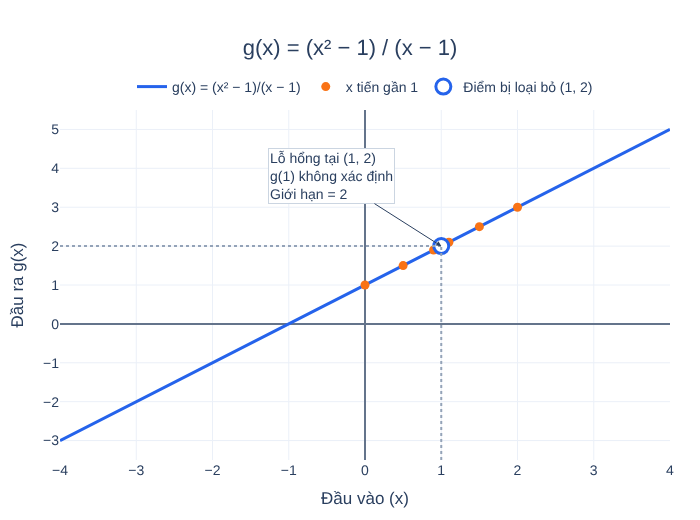

In [17]:
limit_caption = r"""
Xét hàm số \(g(x)=\dfrac{x^2-1}{x-1}\). Hàm số này
<strong>không xác định tại \(x=1\)</strong> vì mẫu số bằng 0
(\(g(1)=\dfrac{0}{0}\)).

<br><br>

Với mọi \(x\neq 1\), ta có thể rút gọn:

\[
g(x)=\frac{(x-1)(x+1)}{x-1}=x+1
\]

Vì vậy, đồ thị của \(g(x)\) là
<strong>đường thẳng \(y=x+1\) bị loại bỏ một điểm duy nhất</strong>
tại \((1,2)\), được biểu thị bằng một
<strong>vòng tròn rỗng</strong>.

<br><br>

<strong>Giới hạn (limit)</strong> khi \(x\) tiến đến 1 là giá trị
\(y\) mà hàm số tiến gần đến, tức là 2:

\[
\lim_{x\to 1}\frac{x^2-1}{x-1}=2
\]

Các điểm màu cam cho thấy: khi \(x\) tiến gần 1 từ bên trái
(0,9; 0,99) hoặc từ bên phải (1,1; 1,01), giá trị \(g(x)\)
đều tiến gần 2.

<br>

<strong>Ý tưởng chính:</strong>

Giới hạn chỉ quan tâm hàm số <em>tiến gần</em> đến giá trị nào,
không yêu cầu hàm số phải xác định tại điểm đó.
Ở đây \(g(1)\) không tồn tại, nhưng giới hạn vẫn bằng 2.
"""


add_caption(
    fig=fig_limit,

    caption=limit_caption,

    title="Tìm hiểu giới hạn và điểm bị loại bỏ",

    html_name="limit_function.html"
)

# Xuất HTML biểu đồ giới hạn

In [18]:
export_figure(
    fig=fig_limit,

    filename="limit_function.html",

    caption=limit_caption,

    caption_title="Tìm hiểu giới hạn và điểm bị loại bỏ",

    page_title="Giới hạn của hàm số - AI From Scratch"
)

Exported successfully: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/limit_function.html
File size: 4726.28 KB


PosixPath('/tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/limit_function.html')

# Tạo index.html

In [19]:
index_html = """<!DOCTYPE html>
<html lang="vi">

<head>

    <meta charset="UTF-8">

    <meta name="viewport"
          content="width=device-width, initial-scale=1.0">

    <title>AI From Scratch - Trực quan hoá hàm số</title>

    <style>

        * {
            box-sizing: border-box;
        }

        body {
            margin: 0;
            padding: 40px 20px;

            font-family: Arial, sans-serif;

            background: #f8fafc;
            color: #1e293b;
        }

        .container {
            width: 100%;
            max-width: 900px;

            margin: 0 auto;
        }

        header {
            text-align: center;
            margin-bottom: 40px;
        }

        header h1 {
            font-size: 32px;
            margin-bottom: 10px;
        }

        header p {
            color: #64748b;
            line-height: 1.7;
        }

        .card {
            display: block;

            padding: 24px;
            margin-bottom: 20px;

            background: white;

            border: 1px solid #e2e8f0;
            border-radius: 12px;

            text-decoration: none;
            color: inherit;

            transition: transform 0.2s;
        }

        .card:hover {
            transform: translateY(-4px);
            border-color: #2563eb;
        }

        .card h2 {
            margin-top: 0;
            color: #2563eb;
        }

        .card p {
            color: #64748b;
            line-height: 1.6;
        }

        footer {
            margin-top: 40px;
            text-align: center;
            color: #94a3b8;
            font-size: 13px;
        }

        @media (max-width: 600px) {

            body {
                padding: 24px 14px;
            }

            header h1 {
                font-size: 25px;
            }

        }

    </style>

</head>

<body>

    <main class="container">

        <header>

            <h1>AI From Scratch</h1>

            <p>
                Các biểu đồ tương tác cho Toán học, Machine Learning và Deep Learning.
            </p>

        </header>


        <section>

            <a class="card"
               href="./linear_function.html">

                <h2>Hàm số bậc nhất</h2>

                <p>
                    Khám phá hàm số f(x) = 2x + 1: hệ số góc, tung độ gốc và tốc độ thay đổi không đổi.
                </p>

            </a>


            <a class="card"
               href="./quadratic_function.html">

                <h2>Hàm số bậc hai</h2>

                <p>
                    Khám phá hàm số g(x) = x&sup2;: đỉnh parabol, tính đối xứng và các điểm nổi bật.
                </p>

            </a>

            <a class="card"
               href="./limit_function.html">

                <h2>Giới hạn của hàm số</h2>

                <p>
                    Khám phá g(x) = (x&sup2; &minus; 1)/(x &minus; 1):
                    đường thẳng y = x + 1 bị loại bỏ điểm (1, 2)
                    và giới hạn khi x tiến đến 1.
                </p>

            </a>

        </section>


        <footer>

            AI From Scratch - Tài liệu học tương tác<br>
            Công thức toán trên mỗi trang cần Internet (MathJax CDN).

        </footer>

    </main>

</body>

</html>
"""


index_path = VISUALIZATION_DIR / "index.html"

index_path.write_text(
    index_html,
    encoding="utf-8"
)

print("Homepage created:", index_path)

Homepage created: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/index.html


# Kiểm tra file đầu ra

Kiểm tra file tồn tại, có nội dung hợp lệ, và link trong `index.html` trỏ đúng file.

In [20]:
import re

expected_files = [
    "index.html",
    "linear_function.html",
    "quadratic_function.html",
    "limit_function.html"
]


print("=" * 55)
print("VISUALIZATION EXPORT REPORT")
print("=" * 55)

all_ok = True

for filename in expected_files:

    file_path = VISUALIZATION_DIR / filename

    if file_path.exists():

        size_kb = file_path.stat().st_size / 1024

        print(f"[SUCCESS] {filename}")
        print(f"          Size: {size_kb:.2f} KB")

    else:

        all_ok = False
        print(f"[FAILED] {filename}")


# Content checks for the chart pages
for filename in ["linear_function.html", "quadratic_function.html", "limit_function.html"]:

    text = (VISUALIZATION_DIR / filename).read_text(encoding="utf-8")

    checks = {
        "doctype": text.startswith("<!DOCTYPE html>"),
        "plotly.js embedded": "plotly.js" in text and len(text) > 1_000_000,
        "plot div": 'class="plotly-graph-div"' in text,
        "caption": 'class="visualization-caption"' in text,
        "MathJax": "mathjax@3" in text,
    }

    for name, ok in checks.items():

        all_ok = all_ok and ok
        print(f"  {filename}: {name:<20} {'OK' if ok else 'MISSING'}")


# Link checks for index.html
index_text = (VISUALIZATION_DIR / "index.html").read_text(encoding="utf-8")

for href in re.findall(r'href="([^"]+)"', index_text):

    target = (VISUALIZATION_DIR / href).resolve()
    ok = target.is_file()

    all_ok = all_ok and ok
    print(f"  index.html link {href:<28} {'OK' if ok else 'BROKEN'}")


print("=" * 55)
print("All checks passed." if all_ok else "Some checks FAILED.")

assert all_ok, "Export validation failed"

VISUALIZATION EXPORT REPORT
[SUCCESS] index.html
          Size: 3.29 KB
[SUCCESS] linear_function.html
          Size: 4719.57 KB
[SUCCESS] quadratic_function.html
          Size: 4722.59 KB
[SUCCESS] limit_function.html
          Size: 4726.28 KB
  linear_function.html: doctype              OK
  linear_function.html: plotly.js embedded   OK
  linear_function.html: plot div             OK
  linear_function.html: caption              OK
  linear_function.html: MathJax              OK
  quadratic_function.html: doctype              OK
  quadratic_function.html: plotly.js embedded   OK
  quadratic_function.html: plot div             OK
  quadratic_function.html: caption              OK
  quadratic_function.html: MathJax              OK
  limit_function.html: doctype              OK
  limit_function.html: plotly.js embedded   OK
  limit_function.html: plot div             OK
  limit_function.html: caption              OK
  limit_function.html: MathJax              OK
  index.html link ./l

# Mở trực quan hoá trên máy

Mở file HTML đã export bằng trình duyệt mặc định (an toàn hơn `IFrame` với đường dẫn tương đối, vốn phụ thuộc vào Jupyter server root). Đặt `OPEN_IN_BROWSER = True` để mở.

In [21]:
import webbrowser

OPEN_IN_BROWSER = False

index_uri = (VISUALIZATION_DIR / "index.html").as_uri()

print("Local preview:", index_uri)

if OPEN_IN_BROWSER:
    webbrowser.open(index_uri)

Local preview: file:///tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/index.html
